  СИСТЕМА АВТОМАТИЧЕСКОЙ ФИЛЬТРАЦИИ ОБЛАЧНОСТИ «СПУТНИКС»
Загрузка датасета | Устройство: CPU
         Загружено снимков: 160 (Обучение: 128)

Обучение нейросети U-Net...
         Эпоха 1/2 | Батч 4/16 | Loss: 0.7890
         Эпоха 1/2 | Батч 8/16 | Loss: 0.6317
         Эпоха 1/2 | Батч 12/16 | Loss: 0.5478
         Эпоха 1/2 | Батч 16/16 | Loss: 0.5310
         -> Эпоха 1 завершена за 69.2с
         Эпоха 2/2 | Батч 4/16 | Loss: 0.4773
         Эпоха 2/2 | Батч 8/16 | Loss: 0.5143
         Эпоха 2/2 | Батч 12/16 | Loss: 0.5321
         Эпоха 2/2 | Батч 16/16 | Loss: 0.3941
         -> Эпоха 2 завершена за 72.2с

Сегментация тестовых снимков и фильтрация
--------------------------------------------------------------------------------


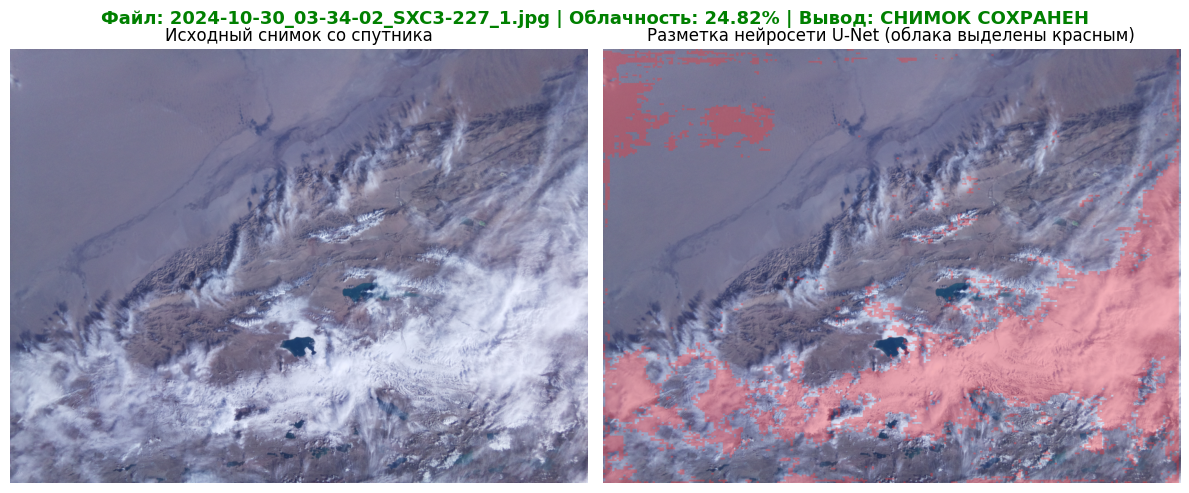

[1] СОХРАНЕН  | 2024-10-30_03-34-02_SXC3-227_1.jpg | Облачность: 24.82% | Схема: visual_results\result_2024-10-30_03-34-02_SXC3-227_1.png


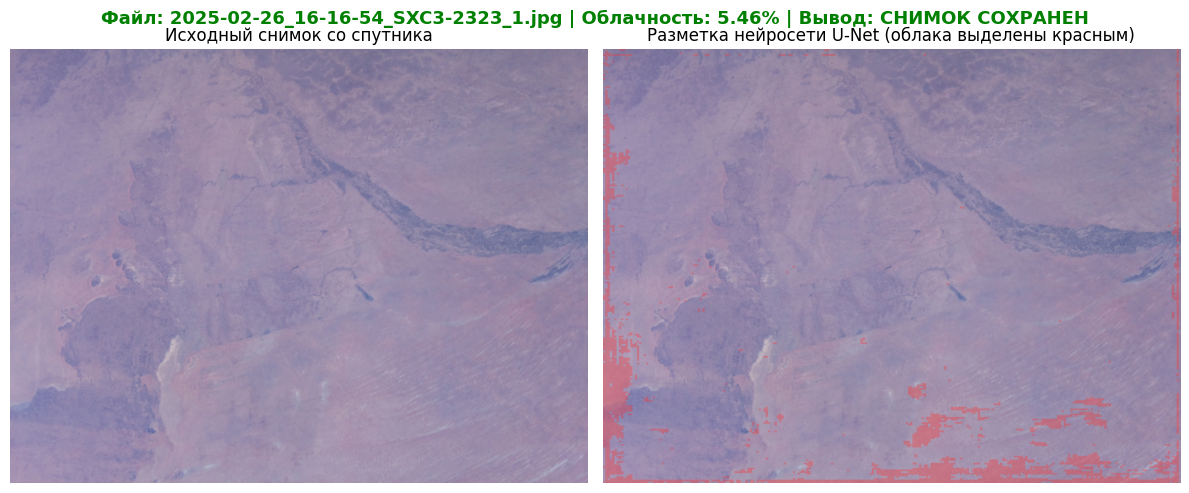

[2] СОХРАНЕН  | 2025-02-26_16-16-54_SXC3-2323_1.jpg | Облачность: 5.46% | Схема: visual_results\result_2025-02-26_16-16-54_SXC3-2323_1.png


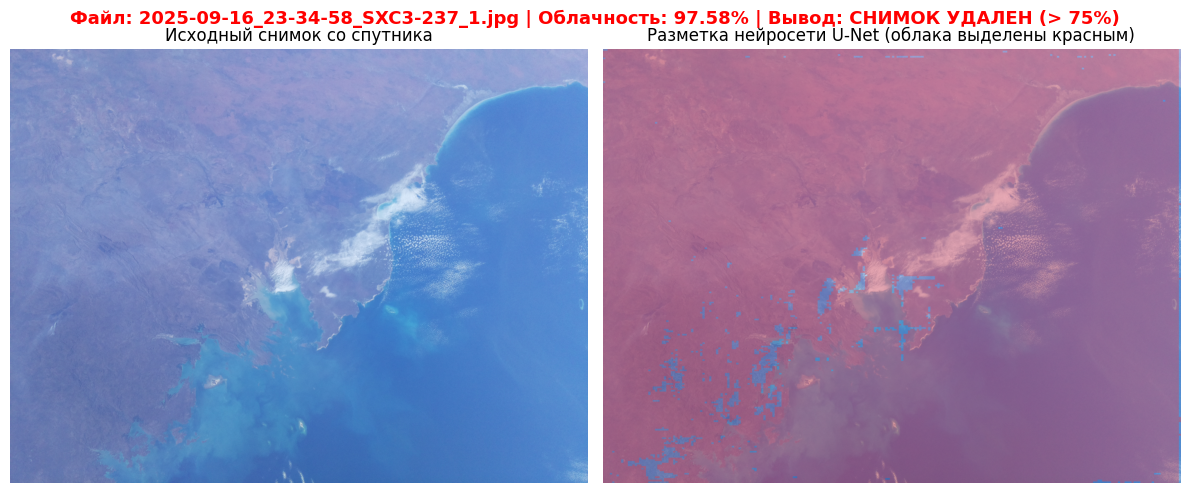

[3] УДАЛЕН    | 2025-09-16_23-34-58_SXC3-237_1.jpg | Облачность: 97.58% | Схема: visual_results\result_2025-09-16_23-34-58_SXC3-237_1.png


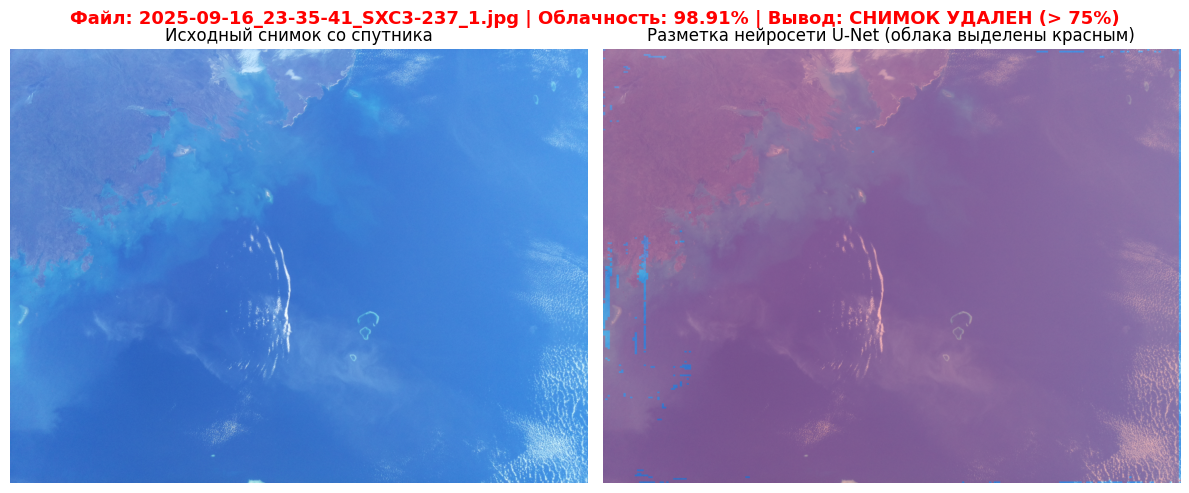

[4] УДАЛЕН    | 2025-09-16_23-35-41_SXC3-237_1.jpg | Облачность: 98.91% | Схема: visual_results\result_2025-09-16_23-35-41_SXC3-237_1.png


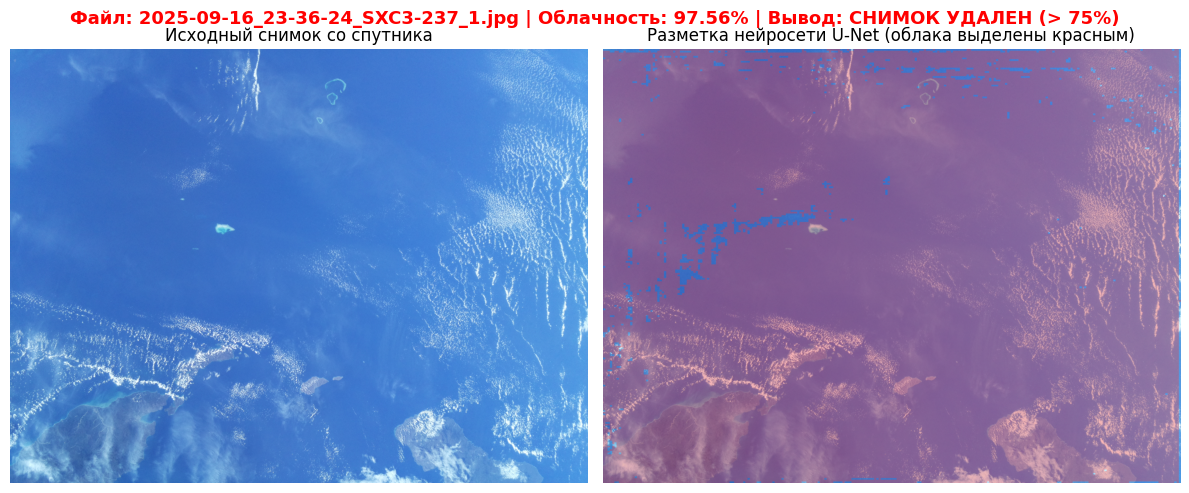

[5] УДАЛЕН    | 2025-09-16_23-36-24_SXC3-237_1.jpg | Облачность: 97.56% | Схема: visual_results\result_2025-09-16_23-36-24_SXC3-237_1.png


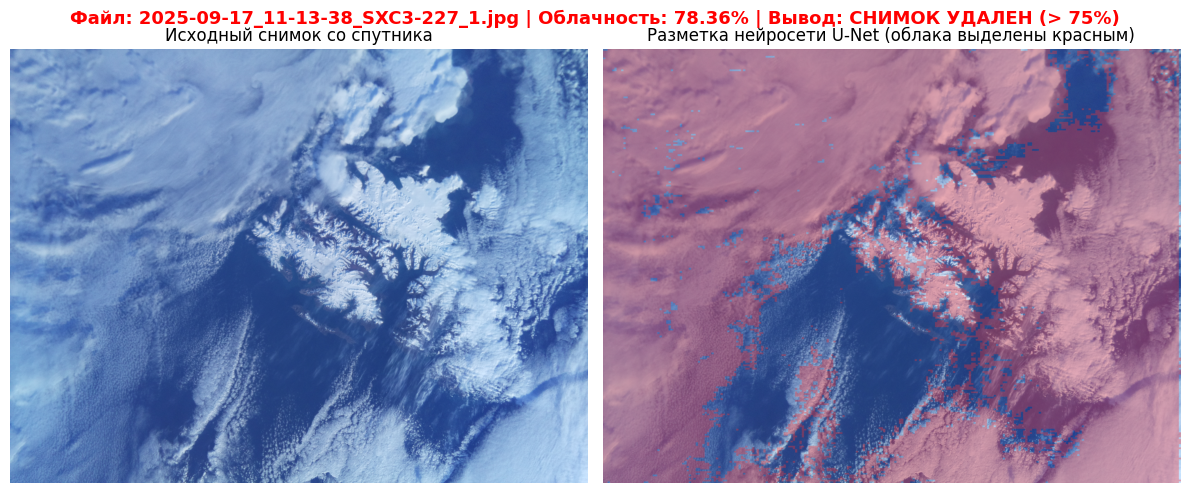

[6] УДАЛЕН    | 2025-09-17_11-13-38_SXC3-227_1.jpg | Облачность: 78.36% | Схема: visual_results\result_2025-09-17_11-13-38_SXC3-227_1.png

  ИТОГОВЫЙ ОТЧЕТ ОПЕРАТОРУ
Всего проверено снимков : 6
Сохранено пригодных     : 2
Удалено облачных (>75%) : 4
Готовые картинки для презентации сохранены в папку: ./visual_results/

[СОХРАНЕННЫЕ ФАЙЛЫ]:
  + 2024-10-30_03-34-02_SXC3-227_1.jpg (24.82%)
  + 2025-02-26_16-16-54_SXC3-2323_1.jpg (5.46%)

[УДАЛЕННЫЕ ФАЙЛЫ]:
  - 2025-09-16_23-34-58_SXC3-237_1.jpg (97.58%)
  - 2025-09-16_23-35-41_SXC3-237_1.jpg (98.91%)
  - 2025-09-16_23-36-24_SXC3-237_1.jpg (97.56%)
  - 2025-09-17_11-13-38_SXC3-227_1.jpg (78.36%)


In [ ]:
import os
import time
import cv2
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import segmentation_models_pytorch as smp


# Визуализация и сохранение снимков
def show_and_save_visual(image_rgb, pred_mask, file_name, cloud_pct, threshold, out_dir="visual_results"):
    os.makedirs(out_dir, exist_ok=True)

    h, w, _ = image_rgb.shape
    mask_resized = cv2.resize(pred_mask, (w, h), interpolation=cv2.INTER_NEAREST)

    overlay = image_rgb.copy()
    overlay[mask_resized > 0.5] = [255, 50, 50]
    blended = cv2.addWeighted(image_rgb, 0.65, overlay, 0.35, 0)

    status = "УДАЛЕН (> 75%)" if cloud_pct > threshold else "СОХРАНЕН"
    status_color = "red" if cloud_pct > threshold else "green"

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle(
        f"Файл: {file_name} | Облачность: {cloud_pct:.2f}% | Вывод: СНИМОК {status}",
        fontsize=13,
        fontweight="bold",
        color=status_color,
    )

    axes[0].imshow(image_rgb)
    axes[0].set_title("Исходный снимок со спутника")
    axes[0].axis("off")

    axes[1].imshow(blended)
    axes[1].set_title("Разметка нейросети U-Net (облака выделены красным)")
    axes[1].axis("off")

    plt.tight_layout()
    save_path = os.path.join(out_dir, f"result_{os.path.splitext(file_name)[0]}.png")
    plt.savefig(save_path, dpi=150)
    plt.show(block=False)
    plt.pause(1.5)
    plt.close(fig)

    return save_path


# Загрузка данных и псевдоразметка
class SputnixCloudDataset(Dataset):
    def __init__(self, img_dir, kml_dir, target_size=(256, 256), max_samples=160):
        self.img_dir = img_dir
        self.kml_dir = kml_dir
        self.target_size = target_size

        all_files = [
            f for f in os.listdir(img_dir) if f.lower().endswith(('.jpg', '.jpeg'))
        ]
        self.img_names = all_files[:max_samples] if max_samples else all_files

        self.to_tensor = T.ToTensor()
        self.normalize = T.Normalize(
            mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
        )

    def __len__(self):
        return len(self.img_names)

    def generate_pseudo_mask(self, image):
        hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
        _, mask = cv2.threshold(hsv[:, :, 2], 175, 255, cv2.THRESH_BINARY)
        return mask

    def __getitem__(self, idx):
        img_name = self.img_names[idx]
        img_path = os.path.join(self.img_dir, img_name)
        image = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)

        mask = self.generate_pseudo_mask(image)
        img_res = cv2.resize(image, self.target_size)
        mask_res = cv2.resize(mask, self.target_size, interpolation=cv2.INTER_NEAREST)

        img_tensor = self.normalize(self.to_tensor(img_res))
        mask_tensor = torch.from_numpy(mask_res).float().unsqueeze(0) / 255.0
        return img_tensor, mask_tensor


# Обучение нейросети и вывод отчета в консоль
def run_sputnix_pipeline():
    PATH_TO_IMAGES = "images"
    PATH_TO_KML = "kml_metadata"
    PATH_TO_TEST = "test_images"
    CLOUD_THRESHOLD = 75.0
    IMG_SIZE = (256, 256)
    DELETE_FILES = False

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    print("=" * 80)
    print("  СИСТЕМА АВТОМАТИЧЕСКОЙ ФИЛЬТРАЦИИ ОБЛАЧНОСТИ «СПУТНИКС»")
    print("=" * 80)
    print(f"Загрузка датасета | Устройство: {str(device).upper()}")

    full_dataset = SputnixCloudDataset(
        PATH_TO_IMAGES, PATH_TO_KML, target_size=IMG_SIZE, max_samples=160
    )
    train_size = int(0.8 * len(full_dataset))
    val_size = len(full_dataset) - train_size
    train_data, _ = torch.utils.data.random_split(full_dataset, [train_size, val_size])
    train_loader = DataLoader(train_data, batch_size=8, shuffle=True, drop_last=True)

    print(f"         Загружено снимков: {len(full_dataset)} (Обучение: {train_size})")

    print("\nОбучение нейросети U-Net...")
    model = smp.Unet(
        encoder_name="resnet34", encoder_weights="imagenet", in_channels=3, classes=1
    ).to(device)

    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

    epochs = 2
    total_batches = len(train_loader)
    for epoch in range(epochs):
        t0 = time.time()
        model.train()
        train_loss = 0.0
        for step, (imgs, masks) in enumerate(train_loader, 1):
            imgs, masks = imgs.to(device), masks.to(device)
            optimizer.zero_grad()
            loss = criterion(model(imgs), masks)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()

            if step % 4 == 0 or step == total_batches:
                print(f"         Эпоха {epoch + 1}/{epochs} | Батч {step}/{total_batches} | Loss: {loss.item():.4f}")

        print(f"         -> Эпоха {epoch + 1} завершена за {time.time() - t0:.1f}с")

    print(f"\nСегментация тестовых снимков и фильтрация")
    print("-" * 80)

    if not os.path.exists(PATH_TO_TEST):
        PATH_TO_TEST = PATH_TO_IMAGES
        test_files = [
            f for f in os.listdir(PATH_TO_TEST) if f.lower().endswith(('.jpg', '.jpeg'))
        ][:6]
    else:
        test_files = [
            f for f in os.listdir(PATH_TO_TEST) if f.lower().endswith(('.jpg', '.jpeg'))
        ]

    to_tensor = T.ToTensor()
    normalize = T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

    saved_files = []
    deleted_files = []

    model.eval()
    with torch.no_grad():
        for idx, file_name in enumerate(test_files, 1):
            file_path = os.path.join(PATH_TO_TEST, file_name)
            bgr = cv2.imread(file_path)
            if bgr is None:
                continue

            rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
            res = cv2.resize(rgb, IMG_SIZE)
            tensor = normalize(to_tensor(res)).unsqueeze(0).to(device)

            logits = model(tensor)
            mask_np = (torch.sigmoid(logits) > 0.5).float().squeeze().cpu().numpy()
            cloud_pct = float(mask_np.mean() * 100.0)

            saved_img_path = show_and_save_visual(
                rgb, mask_np, file_name, cloud_pct, CLOUD_THRESHOLD
            )

            if cloud_pct > CLOUD_THRESHOLD:
                if DELETE_FILES:
                    os.remove(file_path)
                deleted_files.append((file_name, cloud_pct))
                print(f"[{idx}] УДАЛЕН    | {file_name} | Облачность: {cloud_pct:.2f}% | Схема: {saved_img_path}")
            else:
                saved_files.append((file_name, cloud_pct))
                print(f"[{idx}] СОХРАНЕН  | {file_name} | Облачность: {cloud_pct:.2f}% | Схема: {saved_img_path}")

    # Отчет в консоль
    print("\n" + "=" * 80)
    print("  ИТОГОВЫЙ ОТЧЕТ ОПЕРАТОРУ")
    print("=" * 80)
    print(f"Всего проверено снимков : {len(saved_files) + len(deleted_files)}")
    print(f"Сохранено пригодных     : {len(saved_files)}")
    print(f"Удалено облачных (>75%) : {len(deleted_files)}")
    print(f"Готовые картинки для презентации сохранены в папку: ./visual_results/")

    print("\n[СОХРАНЕННЫЕ ФАЙЛЫ]:")
    for name, pct in saved_files:
        print(f"  + {name} ({pct:.2f}%)")

    print("\n[УДАЛЕННЫЕ ФАЙЛЫ]:")
    for name, pct in deleted_files:
        print(f"  - {name} ({pct:.2f}%)")
    print("=" * 80)


if __name__ == "__main__":
    run_sputnix_pipeline()
